# Stage 1: MH107, 314-gene panel

Raw Xenium data → QC → normalisation → saved inputs → gene-set scoring → `cell_class_threshold` → Nhood enrichment.

Some labels were changed by hand using `anno`, under the rule in the parameters cell, so the labels partly depend on the clusters. PCA and UMAP come from the saved object. Section 6 tests how much recalculating PCA changes the labels and Nhood z-scores.

## Parameters

In [ ]:
# Folders: set these before running (papermill parameters)
RAW_DATA_DIR = "/path/to/raw_xenium"  # one subfolder per sample, with cell_feature_matrix.h5 and cells.csv
SAVED_OBJECT_DIR = "/path/to/saved_objects"
LABEL_TABLE_DIR = "/path/to/label_tables"
OUTPUT_ROOT = "/path/to/stage1_output"

In [1]:
SAMPLE = "MH107_314"

# Inputs (read only)
RAW_DIR = f"{RAW_DATA_DIR}/{SAMPLE}"
SAVED_OBJECT = f"{SAVED_OBJECT_DIR}/MH107_0010617_region2_setseed_v2.h5ad"  # file name as in Xenium_314.tar
COUNTS_CSV = f"{LABEL_TABLE_DIR}/{SAMPLE}.csv"

# Outputs
OUTPUT_DIR = f"{OUTPUT_ROOT}/{SAMPLE}"

# Seeds
GLOBAL_SEED = 36
NHOOD_SEED = 112233
PCA_SEED = 36  # used only by the robustness check

# QC
CROP = dict(x_min=0, x_max=8300, y_min=350, y_max=5000)
GENES_TO_REMOVE = []
MIN_COUNTS = 20
MIN_CELLS = 5

# Clustering
N_NEIGHBORS = 15
LEIDEN_RESOLUTION = 3.0
LEIDEN_KEY = f"leiden_{LEIDEN_RESOLUTION}"

# Gene-set scoring
SCORE_QUANTILE = 0.55
LABEL_KEY = "cell_class_threshold"

def apply_label_changes(labels, anno):
    # Hand-changed labels in the original: reassign some "Unclassified" cells using the cluster-based annotation
    mask = labels == "Unclassified"
    labels.loc[mask] = anno.loc[mask].map({
        "vSMCs": "SMCs",        # keep as SMCs
        "CAFs_MYO": "CAFs_MYO",  # reassign to CAFs_MYO
        "Malignant cells": "Malignant cells",
        "TAMs_SPP1_OLR1": "TAMs_SPP1",
        "CAFs_CXCL14": "CAFs_CXCL14",
        "Endothelial": "Endothelial",
    }).fillna("Unclassified")  # fallback used in the original
    return labels

# Nhood enrichment
RADIUS_UM = 50

# Marker genes for reviewing labels
label_markers = ["MUC5B", "ONECUT2", "SLC4A4", "CFTR", "MUC6", "KRT17", "KRT19", "KRT5", "KRT8", "PDGFC", "CXCL14", "COL11A1", "CPA3", "KIT", "MS4A2", "PDGFRA", "C7", "SCN7A", "ABCA6", "ABCA10", "PLA2G2A", "IGF1", "PDPN", "FLT4", "LYVE1", "CCL21", "CDH19", "CHL1", "NGFR", "PLVAP", "VWF", "FLT1", "PDGFRB", "RGS5", "GJC1", "ACTA2", "CALD1", "SPP1", "APOE", "GRN", "CSF1R", "CD86", "HLA-DQA1", "OLR1", "HBEGF", "C1QA", "SELENOP", "C1QC", "HLA-DMB", "MZB1", "IGHG1", "ICAM1", "CCL19", "FOXP3", "IKZF2", "TIGIT", "GNLY", "NKG7", "KLRD1", "IL7R", "TCF7", "CD4", "CD8A", "GZMA", "GZMK", "CLEC10A", "CD1C", "MS4A1", "CD52", "CD19", "IRF8", "CLEC9A", "IDO1", "LAMP3", "CCL22"]

# Cluster annotation
cluster_anno = {
    "0": "Mixed cells",
    "1": "CAFs_CXCL14",
    "2": "Malignant cells",
    "3": "CAFs_MYO",
    "4": "CAFs_MYO",
    "5": "CAFs_CXCL14",
    "6": "Malignant cells",
    "7": "Malignant cells",
    "8": "Mixed cells",
    "9": "TAMs_SPP1_OLR1",
    "10": "CAFs_MYO",
    "11": "Mixed cells",
    "12": "CAFs_MYO",
    "13": "Unassigned",
    "14": "Malignant cells",
    "15": "CAFs_MYO",
    "16": "FRCs",
    "17": "Endothelial",
    "18": "CAFs_NRT",
    "19": "CAFs_CXCL14",
    "20": "CAFs_MYO",
    "21": "CAFs_MYO",
    "22": "Endothelial",
    "23": "vSMCs",
    "24": "Malignant cells",
    "25": "CAFs_MYO",
    "26": "Mast",
    "27": "CAFs_MYO",
    "28": "Mixed cells",
    "29": "TAMs_SPP1_OLR1",
    "30": "CAFs_CXCL14",
    "31": "Mixed cells"}

# Gene sets
gene_sets = {
    'Malignant cells': ['KRT19','KRT17','KRT5','KRT8'],
    'Ductal MUC5B': ['ONECUT2','SLC4A4'],
    'Endocrine': ['INS','GCG','SST'],
    'FRCs': ['PLA2G2A','PDPN','IGF1','PDGFRA'],
    'TRCs': ["CCL19","PDGFRA","ICAM1"],
    'LECs': ['LYVE1','FLT4','PDPN','CCL21'],
    'Endothelial' : ['VWF','PLVAP','FLT1'],
    'SMCs' : ['ACTA2','RGS5'],
    'Pericytes': ['PDGFRB','RGS5','GJC1','CSPG4'],
    'Schwann': ['CDH19','CHL1','NGFR'],
    'CAFs_MYO': ['POSTN','COL11A1','PDGFC','FN1'],
    'CAFs_CXCL14': ['POSTN','COL11A1','CXCL14'],
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA6','ABCA10'],
    'NK': ['GNLY', 'NKG7','KLRC1'],
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    'CD8 T cells': ['CD8A','CD8B','GZMB','GZMA'],
    'B cells': ['MS4A1','CD52','CD19'],
    'Plasma': ['MZB1'],
    'DC1' : ['CLEC9A','IRF8','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' :['CPA3','KIT','TPSAB1'],
    'TAMs_SPP1' : ['GRN','APOE','SPP1'],
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','SLC40A1'],
    'TAMs_MHC' : ['CD86','HLA-DRB1','HLA-DRB5','CSF1R']
}

In [2]:
import importlib
import os
import random
import sys

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

from sklearn.metrics import adjusted_rand_score

np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)

assert os.path.exists(SAVED_OBJECT), f"Saved object not found: {SAVED_OBJECT}"
assert os.path.dirname(SAVED_OBJECT) != OUTPUT_DIR, "OUTPUT_DIR must not hold the saved object"
os.makedirs(OUTPUT_DIR, exist_ok=True)

packages = ["scanpy", "squidpy", "anndata", "numpy", "scipy", "pandas", "sklearn", "umap", "pynndescent",
            "numba", "leidenalg", "igraph", "h5py", "matplotlib", "seaborn"]
software = pd.DataFrame(
    [(p, getattr(importlib.import_module(p), "__version__", "unknown")) for p in packages],
    columns=["package", "version"],
)
software.to_csv(os.path.join(OUTPUT_DIR, "software_versions.tsv"), sep="\t", index=False)
print("python:", sys.version)
display(software)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


python: 3.9.18 (main, Sep 11 2023, 13:41:44) 
[GCC 11.2.0]


,package,version
0,scanpy,1.9.5
1,squidpy,1.3.1
2,anndata,0.10.8
3,numpy,1.24.4
4,scipy,1.9.1
5,pandas,2.3.3
6,sklearn,1.3.2
7,umap,0.5.4
8,pynndescent,0.5.10
9,numba,0.60.0


## 1. Load raw data and QC

In [3]:
adata = sc.read_10x_h5(os.path.join(RAW_DIR, "cell_feature_matrix.h5"))
df = pd.read_csv(os.path.join(RAW_DIR, "cells.csv"))
df.set_index(adata.obs_names, inplace=True)
adata.obs = df.copy()
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].copy().to_numpy()
print(f"Raw: {adata.n_obs} cells")

if CROP is not None:
    criteria = (
        (adata.obs["x_centroid"] >= CROP["x_min"]) & (adata.obs["x_centroid"] <= CROP["x_max"]) &
        (adata.obs["y_centroid"] >= CROP["y_min"]) & (adata.obs["y_centroid"] <= CROP["y_max"])
    )
    adata = adata[criteria, :].copy()
    print(f"After crop: {adata.n_obs} cells")

Raw: 101212 cells
After crop: 98344 cells


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be

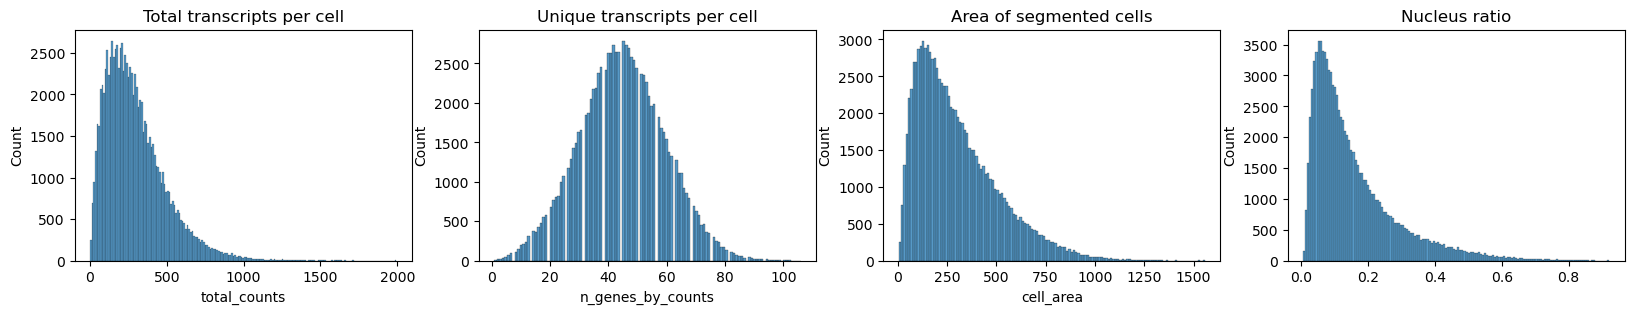

After QC: 97631 cells, 314 genes


In [4]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

fig, axs = plt.subplots(1, 4, figsize=(20, 3))
axs[0].set_title("Total transcripts per cell")
sns.histplot(adata.obs["total_counts"], kde=False, ax=axs[0])
axs[1].set_title("Unique transcripts per cell")
sns.histplot(adata.obs["n_genes_by_counts"], kde=False, ax=axs[1])
axs[2].set_title("Area of segmented cells")
sns.histplot(adata.obs["cell_area"], kde=False, ax=axs[2])
axs[3].set_title("Nucleus ratio")
sns.histplot(adata.obs["nucleus_area"] / adata.obs["cell_area"], kde=False, ax=axs[3])
plt.show()

if GENES_TO_REMOVE:
    adata = adata[:, ~adata.var_names.isin(GENES_TO_REMOVE)].copy()

sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)
print(f"After QC: {adata.n_obs} cells, {adata.n_vars} genes")

## 2. Normalisation

In [5]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)

# Scaled values are kept for plotting only
adata.layers["scaled"] = sc.pp.scale(adata, copy=True).X

## 3. Review of tissue and cell quality

~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scat

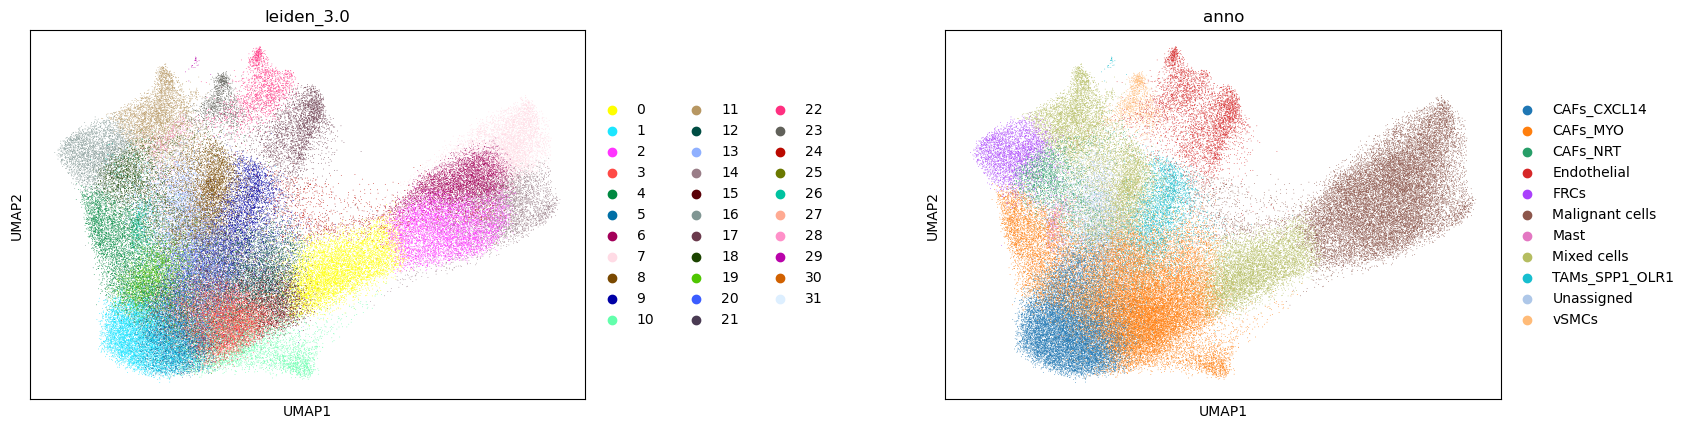

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


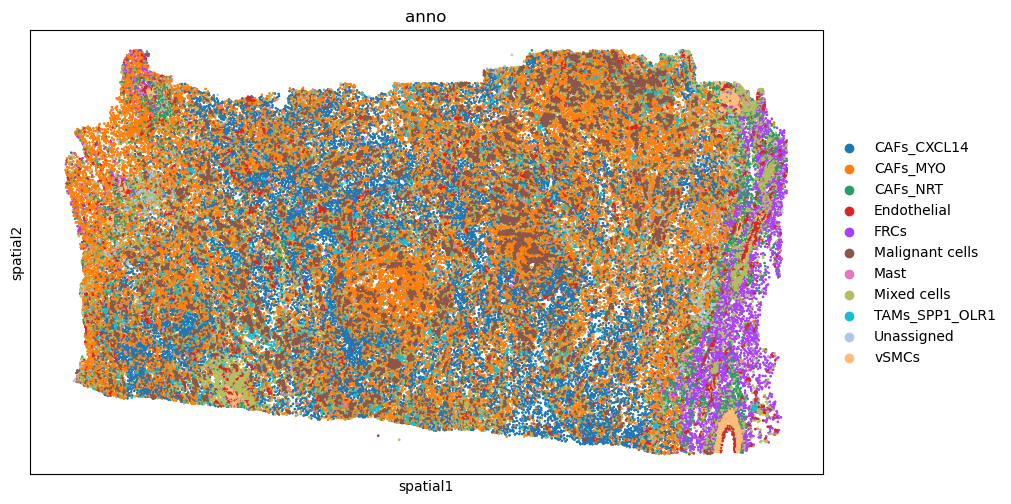

In [6]:
saved = sc.read_h5ad(SAVED_OBJECT, backed="r")
assert list(saved.obs_names) == list(adata.obs_names), "Saved object does not have the same cells in the same order"
assert list(saved.var_names) == list(adata.var_names), "Saved object does not have the same genes in the same order"

adata.obsm["X_pca"] = np.asarray(saved.obsm["X_pca"])
adata.obsm["X_umap"] = np.asarray(saved.obsm["X_umap"])
adata.varm["PCs"] = np.asarray(saved.varm["PCs"])
adata.uns["pca"] = {key: np.asarray(value) if not isinstance(value, dict) else dict(value)
                    for key, value in saved.uns["pca"].items()}
saved.file.close()

sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, random_state=GLOBAL_SEED)
sc.tl.leiden(adata, resolution=LEIDEN_RESOLUTION, key_added=LEIDEN_KEY, random_state=GLOBAL_SEED)

clusters_found, clusters_mapped = set(adata.obs[LEIDEN_KEY].cat.categories), set(cluster_anno)
assert clusters_found == clusters_mapped, f"Clusters differ from cluster_anno: {sorted(clusters_found ^ clusters_mapped)}"
adata.obs["anno"] = adata.obs[LEIDEN_KEY].map(cluster_anno).astype("category")

sc.pl.umap(adata, color=[LEIDEN_KEY, "anno"], wspace=0.5)
sq.pl.spatial_scatter(adata, library_id="spatial", shape=None, color=["anno"], size=2, figsize=(10, 10))

## 4. Gene-set scoring and labels

In [7]:
def assign_labels(data):
    """Score the gene sets, then give each cell its top label if the score reaches the threshold."""
    for cell_type, genes in gene_sets.items():
        sc.tl.score_genes(data, gene_list=genes, score_name=f"{cell_type}_score")

    columns = [f"{cell_type}_score" for cell_type in gene_sets.keys()]
    scores = data.obs[columns]
    threshold = scores.quantile(SCORE_QUANTILE).max()  # the highest SCORE_QUANTILE quantile across all gene sets

    data.obs["max_score"] = scores.max(axis=1)
    labels = scores.idxmax(axis=1).str.replace("_score", "")
    labels[data.obs["max_score"] < threshold] = "Unclassified"
    return threshold, labels, columns


threshold, base_labels, score_columns = assign_labels(adata)
print(f"Threshold: {threshold}")
print(f"Cells below threshold: {int((base_labels == 'Unclassified').sum())} of {adata.n_obs}")


Threshold: 0.9075795698165894
Cells below threshold: 21068 of 97631


In [8]:
def final_labels(labels, anno):
    labels = apply_label_changes(labels.copy(), anno)
    return labels.astype("category")


adata.obs[LABEL_KEY] = final_labels(base_labels, adata.obs["anno"].astype(str))
print(adata.obs[LABEL_KEY].value_counts())

cell_class_threshold
CAFs_MYO           27585
CAFs_CXCL14        23739
Malignant cells    20771
Unclassified        9547
Endothelial         3658
FRCs                2441
TAMs_SPP1           1867
SMCs                1837
Mast                1164
TAMs_C1QC            681
Pericytes            580
Migratory DCs        517
TAMs_MHC             448
TAMs_OLR1            388
CD4 T cells          366
Plasma               339
CAFs_NRT             269
B cells              249
DC1                  213
LECs                 204
Ductal MUC5B         154
DC2                  145
TRCs                 135
Schwann              107
NK                    93
CD4 Treg              73
CD8 T cells           61
Name: count, dtype: int64


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureW

~/.local/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = rep_df.groupby(level=0).mean()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


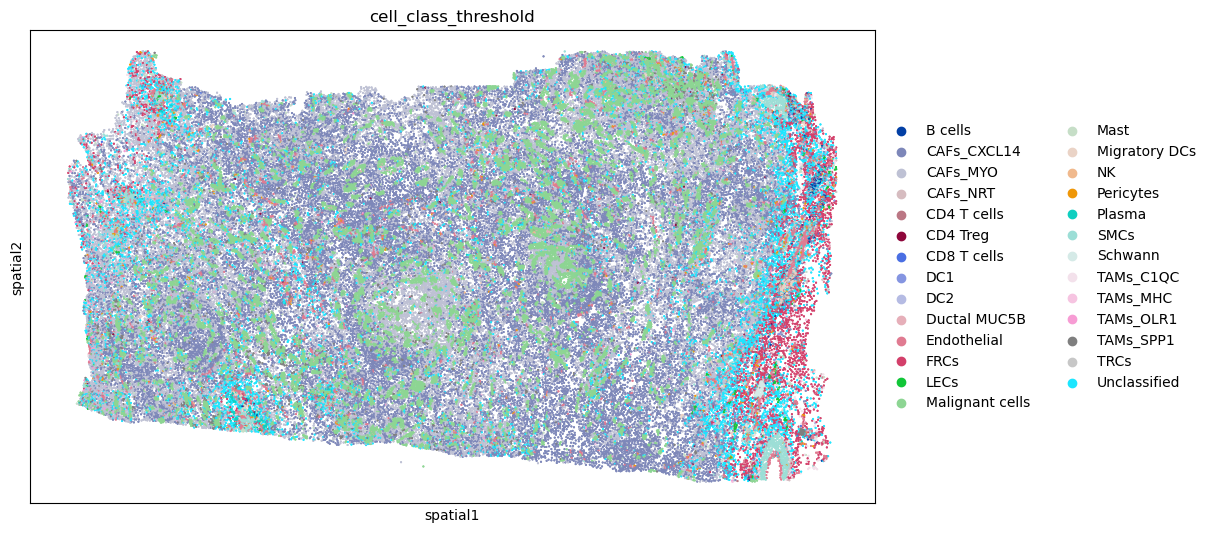

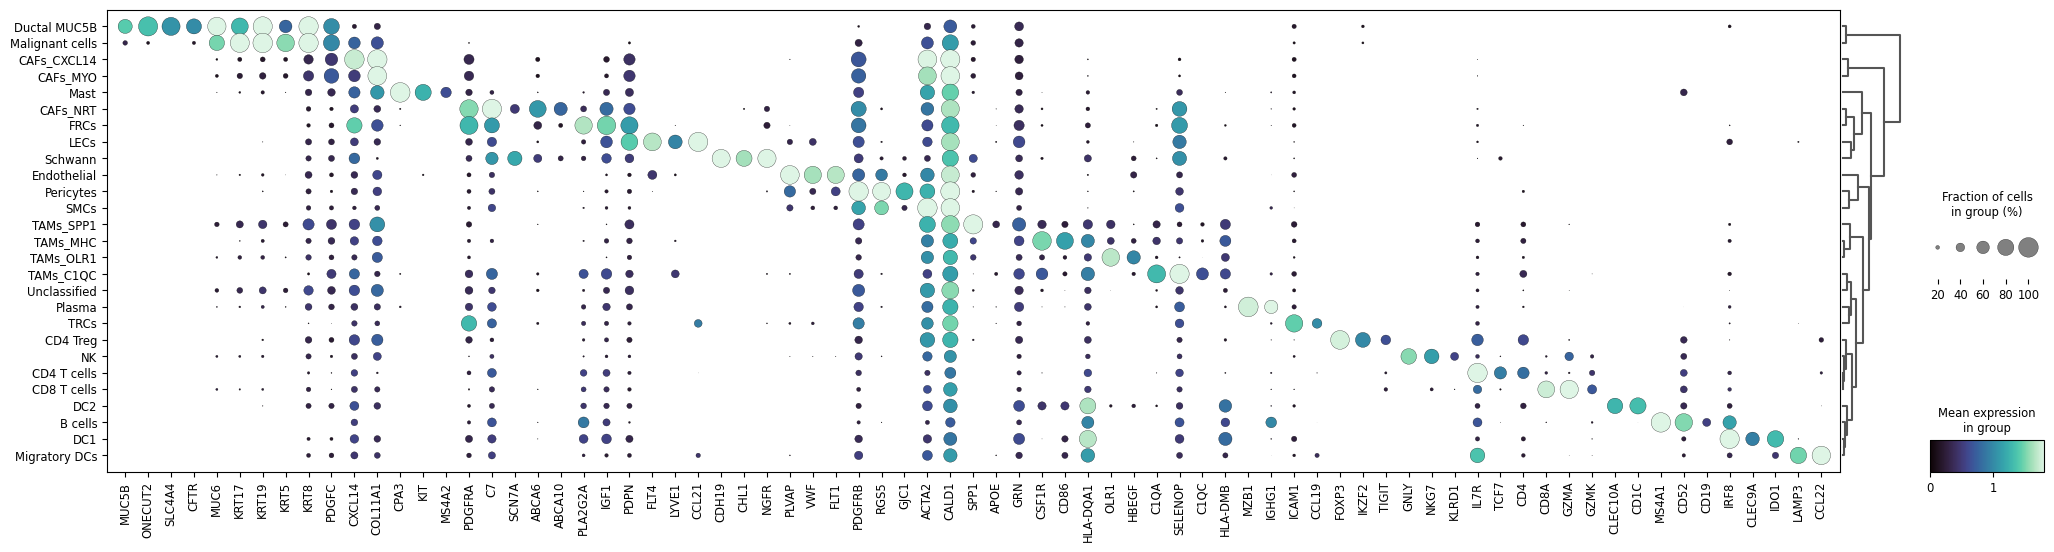

In [9]:
sq.pl.spatial_scatter(adata, shape=None, color=[LABEL_KEY], size=1, library_id="spatial", figsize=(12, 10))

sc.pl.dotplot(adata, var_names=[g for g in dict.fromkeys(label_markers) if g in adata.var_names], groupby=LABEL_KEY,
              figsize=(25, 6), vmax=1.8, vmin=0, dot_min=0.1, cmap="mako", dendrogram=True)

## 5. Nhood enrichment

  0%|          | 0/1000 [00:00<?, ?/s]

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
~/.local/lib/python3.9/site-packages/squidpy/pl/_utils.py:556: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  row_labels = adata.obs[key][row_order]


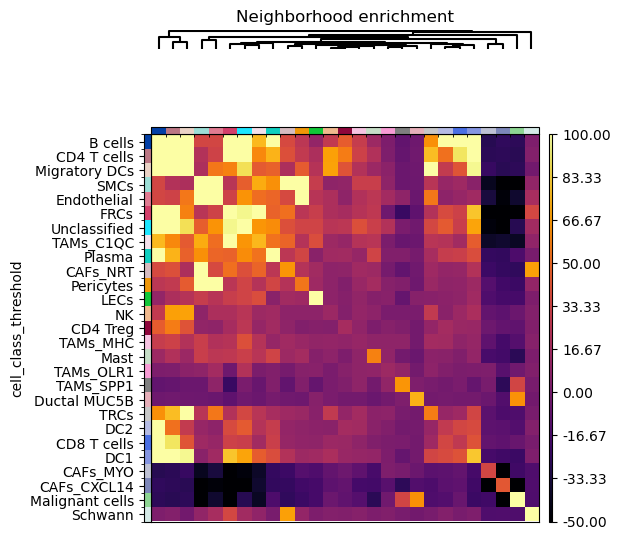

In [10]:
sq.gr.spatial_neighbors(adata, coord_type="generic", spatial_key="spatial", radius=RADIUS_UM)
sq.gr.nhood_enrichment(adata, cluster_key=LABEL_KEY, seed=NHOOD_SEED)
sq.pl.nhood_enrichment(adata, cluster_key=LABEL_KEY, method="average", cmap="inferno",
                       vmin=-50, vmax=100, figsize=(5, 5))

## 6. Robustness check: recalculated PCA

This recalculates PCA and clusters, applies the same label rule to the new clusters and repeats Nhood enrichment. Gene-set scores don't use PCA, so they aren't repeated.

In [11]:
def compare_nhood(first, second):
    """Correlation and largest difference of Nhood z-scores, across the labels in both objects."""
    key = f"{LABEL_KEY}_nhood_enrichment"
    cats_first = list(first.obs[LABEL_KEY].astype("category").cat.categories)
    cats_second = list(second.obs[LABEL_KEY].astype("category").cat.categories)
    shared = [c for c in cats_first if c in cats_second]
    z_first = pd.DataFrame(first.uns[key]["zscore"], index=cats_first, columns=cats_first).loc[shared, shared].values
    z_second = pd.DataFrame(second.uns[key]["zscore"], index=cats_second, columns=cats_second).loc[shared, shared].values
    valid = ~(np.isnan(z_first) | np.isnan(z_second))
    labels_differ = sorted(set(cats_first) ^ set(cats_second))
    return np.corrcoef(z_first[valid], z_second[valid])[0, 1], np.abs(z_first[valid] - z_second[valid]).max(), labels_differ


robust = sc.AnnData(adata.X, obs=adata.obs[[]].copy(), var=adata.var[[]].copy())
sc.pp.pca(robust, random_state=PCA_SEED)
sc.pp.neighbors(robust, n_neighbors=N_NEIGHBORS, random_state=GLOBAL_SEED)
sc.tl.leiden(robust, resolution=LEIDEN_RESOLUTION, key_added="leiden_recalculated_pca", random_state=GLOBAL_SEED)
recalculated_clusters = robust.obs["leiden_recalculated_pca"].astype(str)

# Each recalculated cluster takes the annotation most of its cells had, then the same label rules are applied
recalculated_anno = recalculated_clusters.map(
    pd.crosstab(recalculated_clusters, adata.obs["anno"].astype(str)).idxmax(axis=1)
)

test = sc.AnnData(adata.X, obs=adata.obs[[]].copy(), var=adata.var[[]].copy())
test.obsm["spatial"] = adata.obsm["spatial"].copy()
test.obs[LABEL_KEY] = final_labels(base_labels, recalculated_anno).values
sq.gr.spatial_neighbors(test, coord_type="generic", spatial_key="spatial", radius=RADIUS_UM)
sq.gr.nhood_enrichment(test, cluster_key=LABEL_KEY, seed=NHOOD_SEED)

# Keep the per-cell labels for testing niche stability in Stage 2
pd.DataFrame({
    "cell_index": test.obs_names,
    "x_centroid": test.obsm["spatial"][:, 0],
    "y_centroid": test.obsm["spatial"][:, 1],
    LABEL_KEY: test.obs[LABEL_KEY].astype(str).values,
}).to_csv(os.path.join(OUTPUT_DIR, "recalculated_labels.csv.gz"), index=False)

same_label = (test.obs[LABEL_KEY].astype(str).values == adata.obs[LABEL_KEY].astype(str).values).mean()
z_correlation, z_difference, labels_differ = compare_nhood(adata, test)

robustness = pd.DataFrame(
    [
        ("Same label", f"{same_label:.4%}"),
        ("Nhood z-score correlation", f"{z_correlation:.4f}"),
        ("Nhood z-score, max difference", f"{z_difference:.3g}"),
        ("Labels only in one result", labels_differ),
        ("Adjusted Rand index", f"{adjusted_rand_score(adata.obs[LEIDEN_KEY].astype(str), recalculated_clusters):.4f}"),
    ],
    columns=["measure", "value"],
)
robustness.to_csv(os.path.join(OUTPUT_DIR, "robustness_summary.tsv"), sep="\t", index=False)
display(robustness)

  0%|          | 0/1000 [00:00<?, ?/s]

,measure,value
0,Same label,98.3202%
1,Nhood z-score correlation,0.9999
2,"Nhood z-score, max difference",5.56
3,Labels only in one result,[]
4,Adjusted Rand index,0.6908


## 7. Save outputs

In [12]:
adata.write_h5ad(os.path.join(OUTPUT_DIR, f"{SAMPLE}.h5ad"))

# Values in this file are adata.X (log-normalised), not raw counts
metadata = pd.DataFrame({
    "x_location": adata.obs["x_centroid"].values,
    "y_location": adata.obs["y_centroid"].values,
    "cluster_based_annotation": adata.obs["anno"].values,
    "gene_set_scoring_annotation": adata.obs[LABEL_KEY].values,
    "transcript_counts": adata.obs["transcript_counts"].values,
}, index=adata.obs_names)
expression = pd.DataFrame(adata.X.toarray(), index=adata.obs_names, columns=adata.var_names)
pd.concat([metadata, expression], axis=1).to_csv(os.path.join(OUTPUT_DIR, f"{SAMPLE}.csv"), index=False)
del expression

## 8. Check against the saved object

In a passing run, `Same label` is 100%, the score difference is 0 and the Nhood correlation is 1.

In [14]:
reference = sc.read_h5ad(SAVED_OBJECT, backed="r")
assert list(adata.obs_names) == list(reference.obs_names), "Cells differ from the saved object"

same_label = (adata.obs[LABEL_KEY].astype(str).values == reference.obs[LABEL_KEY].astype(str).values).mean()
score_difference = np.abs(adata.obs[score_columns].values - reference.obs[score_columns].values).max()

key = f"{LABEL_KEY}_nhood_enrichment"
categories = list(adata.obs[LABEL_KEY].cat.categories)
reference_categories = list(reference.obs[LABEL_KEY].astype("category").cat.categories)
assert set(categories) == set(reference_categories), f"Labels differ: {sorted(set(categories) ^ set(reference_categories))}"
z_new = adata.uns[key]["zscore"]
z_reference = pd.DataFrame(reference.uns[key]["zscore"], index=reference_categories, columns=reference_categories).loc[categories, categories].values
valid = ~(np.isnan(z_new) | np.isnan(z_reference))

check = [
    ("Cells", adata.n_obs),
    ("Same label", f"{same_label:.4%}"),
    ("Gene-set scores, max difference", f"{score_difference:.3g}"),
    ("Nhood z-score correlation", f"{np.corrcoef(z_new[valid], z_reference[valid])[0, 1]:.4f}"),
    ("Nhood z-score, max difference", f"{np.abs(z_new[valid] - z_reference[valid]).max():.3g}"),
]
reference.file.close()

if os.path.exists(COUNTS_CSV):
    csv_labels = pd.read_csv(COUNTS_CSV, usecols=["gene_set_scoring"])["gene_set_scoring"]
    if len(csv_labels) == adata.n_obs:
        check.append(("Same label as counts CSV", f"{(csv_labels.astype(str).values == adata.obs[LABEL_KEY].astype(str).values).mean():.4%}"))

check = pd.DataFrame(check, columns=["measure", "value"])
check.to_csv(os.path.join(OUTPUT_DIR, "stage1_check.tsv"), sep="\t", index=False)
display(check)

,measure,value
0,Cells,97631
1,Same label,100.0000%
2,"Gene-set scores, max difference",0
3,Nhood z-score correlation,1.0000
4,"Nhood z-score, max difference",0
5,Same label as counts CSV,100.0000%
